# Overview

This notebook evaluates whether antecedent precipitation accumulation periods improve the modeling of nonstationary warm-temperature extremes across CONUS.

## Methods Summary

- Fit nonstationary GEV models with GLOST as a covariate in the location and scale parameters.
- Compare a temperature-only model ($NoPr$) with models incorporating antecedent precipitation accumulations over 14, 30, 90, and 180 days ($Pr_{14}$, $Pr_{30}$, $Pr_{90}$, $Pr_{180}$).
- Evaluate predictive performance using five-fold cross-validation.
- Calculate CRPS, Dawid-Sebastiani score, and squared error for each fold.
- Apply Algorithm B1 of Auld et al. (2023) to identify statistically significant differences in predictive skill.
- Determine the dominant antecedent precipitation timescale at each grid cell from significant pairwise model victories.
- Examine relationships between dominant timescales and annual precipitation, winter precipitation, elevation, and root-zone soil moisture (ERA5-Land SWVL3).
- Evaluate differences in return-level sensitivity and return-level changes among dominant-timescale classes.

## Objectives

- Identify spatially coherent dominant antecedent precipitation timescales across CONUS.
- Assess the robustness of model-selection results across predictive metrics.
- Investigate environmental characteristics associated with dominant timescale classes.
- Examine how dominant timescales relate to the response of extreme temperatures to climate variability and change.

In [2]:
import numpy as np
import xarray as xr
from pathlib import Path
from itertools import combinations
import cartopy
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
from matplotlib import cm
from matplotlib.transforms import blended_transform_factory

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [19]:
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec
import ensaio
import seaborn as sns

In [4]:
state_borders =cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_1_states_provinces_lakes', scale='50m', facecolor='none')
rivers = cartopy.feature.NaturalEarthFeature(category='physical',name='rivers_lake_centerlines',scale='50m',facecolor='none',edgecolor='blue')

In [5]:
latN = 50
latS = 25
lonW = -119.5
lonE = -74

cLat = (latN + latS)/2
cLon = (lonW + lonE )/2

In [6]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

In [7]:
# ============================================================
# INPUT FILES
# ============================================================
files = {"PrNO": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostLocSca_extremes_gev_1952_2025.nc",\
         "Pr14": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr14LocSca_extremes_gev_1952_2025.nc",
         "Pr30": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr30LocSca_extremes_gev_1952_2025.nc",
         "Pr90": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr90LocSca_extremes_gev_1952_2025.nc",
         "Pr180": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr180LocSca_extremes_gev_1952_2025.nc"}

metrics = ["CRPS_cv","SE_cv","DawSeb_cv"]
models = list(files.keys())
models_name = {"PrNO": "$No Pr$","Pr14": r"$Pr_{14}$", "Pr30": r"$Pr_{30}$",  "Pr90": r"$Pr_{90}$", "Pr180": r"$Pr_{180}$"}
# ============================================================
# READ MODEL DATASETS
# ============================================================
datasets = {}
for model, file in files.items():
    print(f"Reading {model}")
    ds = xr.open_dataset(file)
    for metric in metrics:
        ds[metric] = (ds[metric].load())
    ds['AIC'] = ds['AIC'].load()    
    ds['BIC'] = ds['BIC'].load()    
    ds['rl'] = ds['rl'].load()
    if model=='PrNO':
        ds['covariate1'] = ds['covariate'].load()
    else:
        ds['covariate1'] = ds['covariate1'].load()
    datasets[model] = ds
    return_periods = ds.return_periods.data
    ds.close()
    
AEP = [1/irp for irp in return_periods]
units = '°F'    
# ============================================================
# BUILD PAIR LIST
# ============================================================
pairs = list(combinations(models, 2))
print(pairs)
# ============================================================
# READ ALGORITHM B1 RESULTS
# ============================================================
b1_files = {}
for model0, model1 in pairs:
    file_B1 = (f"/Users/gahe5417/data/TXx/"f"AlgorithmB1_glostpr{model0[2::]}LocSca_vs_glostpr{model1[2::]}LocSca.nc")
    print(f"Reading {Path(file_B1).name}")
    b1_files[(model0, model1)] = xr.open_dataset(file_B1)

landmask = datasets["PrNO"].AIC.notnull()

Reading PrNO
Reading Pr14
Reading Pr30
Reading Pr90
Reading Pr180
[('PrNO', 'Pr14'), ('PrNO', 'Pr30'), ('PrNO', 'Pr90'), ('PrNO', 'Pr180'), ('Pr14', 'Pr30'), ('Pr14', 'Pr90'), ('Pr14', 'Pr180'), ('Pr30', 'Pr90'), ('Pr30', 'Pr180'), ('Pr90', 'Pr180')]
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr14LocSca.nc
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr30LocSca.nc
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr90LocSca.nc
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr180LocSca.nc
Reading AlgorithmB1_glostpr14LocSca_vs_glostpr30LocSca.nc
Reading AlgorithmB1_glostpr14LocSca_vs_glostpr90LocSca.nc
Reading AlgorithmB1_glostpr14LocSca_vs_glostpr180LocSca.nc
Reading AlgorithmB1_glostpr30LocSca_vs_glostpr90LocSca.nc
Reading AlgorithmB1_glostpr30LocSca_vs_glostpr180LocSca.nc
Reading AlgorithmB1_glostpr90LocSca_vs_glostpr180LocSca.nc


In [8]:
model_ids = {"PrNO": 1,"Pr14": 2,"Pr30": 3,"Pr90": 4,"Pr180": 5}

## Dominant Precipitation Covariate Based on Predictive Skill
While pairwise comparisons identify significant differences between individual model pairs, a synthesis is required to determine the overall preferred precipitation covariate at each location.

For a given metric, each model receives one victory for every statistically significant pairwise comparison in which its score is lower than that of its competitor. The number of significant victories is then accumulated across all competing models. Models with the greatest number of victories become candidates for dominance.

When multiple candidates achieve the same number of significant victories, the tie is resolved using the average score itself, with preference given to the model having the lowest mean score. Locations where no model achieves a statistically significant victory are classified as No Winner.

In [9]:
def dominant_model_map(metric,datasets, b1_files, models, alpha=0.05):
    """
    Dominant model based on pairwise Algorithm B1 tests.
    Returns
    1. Count significant pairwise victories (Algorithm B1).
    2. Model(s) with the most wins become candidates.
    3. If several candidates are tied, select the candidate with
       the lowest mean score.
    4. If no model achieves any significant victory, assign 0.
    -------
    dominant :  xr.DataArray(dtype=str)
    """
    metric_name = metric.replace("_cv", "")
    # --------------------------------------------------
    # Mean metric scores
    # --------------------------------------------------
    scores = xr.concat([datasets[m][metric].mean("time") for m in models],dim="model")
    scores = scores.assign_coords(model=models)    
    wins = xr.zeros_like(scores, dtype=np.int16)
    # --------------------------------------------------
    # Count pairwise victories
    # --------------------------------------------------
    for i, model_i in enumerate(models):
        score_i = datasets[model_i][metric].mean("time")
        for j, model_j in enumerate(models):
            if j <= i:
                continue
            score_j = datasets[model_j][metric].mean("time")
            pair = (model_i, model_j)
            ds_b1 = b1_files[pair]
            pval = ds_b1[f"{metric_name}_B1_pvalue"]
            sig = pval <= alpha
            i_wins = sig & (score_i < score_j)
            j_wins = sig & (score_j < score_i)
            wins.loc[dict(model=model_i)] += i_wins.astype(np.int16)
            wins.loc[dict(model=model_j)] += j_wins.astype(np.int16)
    # --------------------------------------------------
    # Determine candidates
    # --------------------------------------------------
    max_wins = wins.max("model")
    candidates = wins == max_wins
    # score used for non-candidates
    dummy_score = float(scores.max( skipna=True) ) + 1
    candidate_scores = xr.where(candidates,  scores, dummy_score)
    # replace remaining NaNs (all-NaN locations)
    candidate_scores = candidate_scores.fillna(dummy_score)
    # tied candidate with lowest score wins
    dominant = candidate_scores.argmin("model").astype(np.int16) + 1
    # no winner if nobody achieved a significant victory
    dominant = xr.where( max_wins == 0, 0,dominant  )
    # --------------------------------------------------
    # Metadata
    # --------------------------------------------------
    dominant.attrs["long_name"] = ( f"Dominant model ({metric_name})")
    dominant.attrs["flag_values"] = ([0] + list(range(1, len(models) + 1)))
    dominant.attrs["flag_meanings"] = ("NoWin " + " ".join(models))

    return dominant

In [10]:
dominant_CRPS = dominant_model_map("CRPS_cv",datasets,b1_files,models,alpha=0.05)
dominant_DawSeb = dominant_model_map("DawSeb_cv",datasets,b1_files,models,alpha=0.05)
dominant_SE = dominant_model_map("SE_cv",datasets,b1_files,models,alpha=0.05)

In [11]:
dom_stack = xr.concat([dominant_CRPS,dominant_DawSeb,dominant_SE],dim="metric")

In [12]:
from scipy.stats import mode
def majority_vote(x):
    x = x[x > 0]
    if len(x) == 0:
        return 0
    vals, counts = np.unique(x, return_counts=True)
    if counts.max() < 2:
        return 0
    return vals[counts.argmax()]

def majority_vote_no_nothing(x):
    """
    Majority vote among valid model selections.
    Assumes:
        0 = NoWin
    Returns:
        NaN if no consensus.
    """
    x = x[x > 0]
    if len(x) == 0:
        return np.nan
    vals, counts = np.unique(x, return_counts=True)
    max_count = counts.max()
    winners = vals[counts == max_count]
    # tie among winners
    if len(winners) > 1:
        return np.nan
    return winners[0]

def agreement_count(x):
    # remove no-winner class
    x = x[x > 0]
    if len(x) == 0:
        return 0
    vals, counts = np.unique( x, return_counts=True )
    return counts.max()

In [13]:
consensus_map = xr.apply_ufunc(majority_vote,dom_stack,input_core_dims=[["metric"]],vectorize=True,output_dtypes=[int])
agreement_map = xr.apply_ufunc(agreement_count,dom_stack,input_core_dims=[["metric"]],vectorize=True,output_dtypes=[np.int16])
agreement_map = agreement_map.where(landmask)
consensus_map = consensus_map.where(landmask)

In [14]:
def plot_categorical_map(da, title,cmap,norm,cbar_labels,ax=None, proj=None,state_borders=None,rivers=None,\
                    show_colorbar=True,show_percentages=True,extent=(-125, -66.5, 24, 50)):
    """
    Generic categorical map plotting function.
    Parameters
    ----------
    da : xr.DataArray
        Categorical map.
    title : str
    cmap : matplotlib colormap
    norm : matplotlib.colors.BoundaryNorm
    cbar_labels : list of str
        Labels corresponding to categories.
    ax : matplotlib axis, optional
    show_colorbar : bool, default=True
    show_percentages : bool, default=True
        Display area-weighted percentages.
    """
    # --------------------------------------------------
    # Figure / Axis
    # --------------------------------------------------
    created_fig = False
    if ax is None:
        fig = plt.figure(figsize=(13, 7))
        ax = plt.axes(projection=proj)
        created_fig = True
    else:
        fig = ax.figure
    da.plot(ax=ax, transform=ccrs.PlateCarree(),cmap=cmap, norm=norm, add_colorbar=False)
    # --------------------------------------------------
    # Map features
    # --------------------------------------------------
    ax.coastlines(linewidth=0.3)
    if state_borders is not None:
        ax.add_feature( state_borders, edgecolor="k",linewidth=0.1,zorder=100)
    if rivers is not None:
        ax.add_feature(rivers, edgecolor="royalblue",linewidth=0.2)
    ax.set_extent( extent,crs=ccrs.PlateCarree() )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')
    # --------------------------------------------------
    # Area percentages
    # --------------------------------------------------
    if show_percentages:
        lat_name = ( "lat"if "lat" in da.coords else "latitude")
        weights = np.cos(np.deg2rad(da[lat_name]))

        total_area = weights.where( np.isfinite(da)).sum().item()
        txt = []
        for iclass, label in enumerate(cbar_labels):
            pct = ( 100 * (da == iclass).weighted(weights).sum().item()/ total_area)
            txt.append(f"{label.replace(chr(10),' ')}: {pct:.1f}%")

        ax.text(0.02,0.02, "\n".join(txt), transform=ax.transAxes,fontsize=11,fontweight="bold",va="bottom", ha="left",bbox=dict(facecolor="white",alpha=0.85,edgecolor="none"))
    # --------------------------------------------------
    # Colorbar
    # --------------------------------------------------
    if show_colorbar:
        ticks = (np.diff(norm.boundaries)/2+ norm.boundaries[:-1])
        cbar = plt.colorbar( plt.cm.ScalarMappable(  cmap=cmap,norm=norm,),ax=ax,orientation="horizontal",pad=0.06,shrink=0.85,ticks=ticks)
        cbar.ax.set_xticklabels(cbar_labels)
        cbar.ax.tick_params(labelsize=12)
        cbar.set_label( "Consensus dominant precipitation covariate",fontsize=14)
    # --------------------------------------------------
    # Title
    # --------------------------------------------------
    ax.set_title(title, fontsize=18,fontweight="bold")

    return fig,ax

In [21]:
dsmean = xr.open_dataset('/Volumes/Data/CMIP6_Large_Ensembles/NClimGrid/AnnualMean/prcp_mean_annual_nclimgrid.nc')
prcp_mean = dsmean['prcp'].load()
dsmean.close()
dsmean = xr.open_dataset('/Volumes/Data/CMIP6_Large_Ensembles/NClimGrid/AnnualMean/prcp_mean_DJF_nclimgrid.nc')
prcp_djf = dsmean['prcp_djf_mean'].load()
dsmean.close()
dssm = xr.open_dataset('/Users/gahe5417/data/TXx/ERA5_Land_CONUS_soil_moisture_layer3_mean_1952_2025.nc')
sm_mean = dssm["swvl3"]
dssm.close()
print("Fetching stable topography data array...")
topo_file_path = ensaio.fetch_earth_topography(version=1)
dstopo = xr.load_dataset(topo_file_path)
topo = dstopo['topography'].sel(longitude=slice(-125, -66.5),latitude=slice(24.4,49.4))
# Extract spatial variables (Ensaio uses standard 'longitude', 'latitude', and 'topography')
lonz = topo.longitude.values
latz = topo.latitude.values
z = topo.values
topo_regrid = topo.interp(longitude=dominant_CRPS.lon,latitude=dominant_CRPS.lat)

Fetching stable topography data array...


In [40]:
classes = { 0: ("NoWin",  np.nan),
    2: ("Pr14",  14),
    3: ("Pr30",  30),
    4: ("Pr90",  90),
    5: ("Pr180", 180),
}
order = [
    "NoWin",
    "Pr14",
    "Pr30",
    "Pr90",
    "Pr180",
]
colors = [
    "#d9d9d9",
    "#fee08b",
    "#91cf60",
    "#66c2a5",
    "#3288bd",
]
palette = {
    "NoWin": "#d9d9d9",
    "Pr14": "#fee08b",
    "Pr30": "#91cf60",
    "Pr90": "#66c2a5",
    "Pr180": "#3288bd",
}

### Figure 1. Dominant Antecedent Precipitation Timescale
Question

What antecedent precipitation accumulation period provides the greatest predictive skill for TXx across CONUS? 

Panels
(a) Dominant antecedent precipitation timescale (CRPS) : The primary model-selection result is based on CRPS because CRPS is a proper scoring rule that evaluates the full predictive distribution and is generally regarded as the most comprehensive measure of probabilistic forecast performance. The dominant-covariate map below therefore represents the primary precipitation-covariate recommendation.<br>
(b) Agreement among predictive metrics (CRPS, DSS, SE)<br>
Key Result
Dominant timescales exhibit coherent spatial organization.
Results are generally robust across verification metrics.

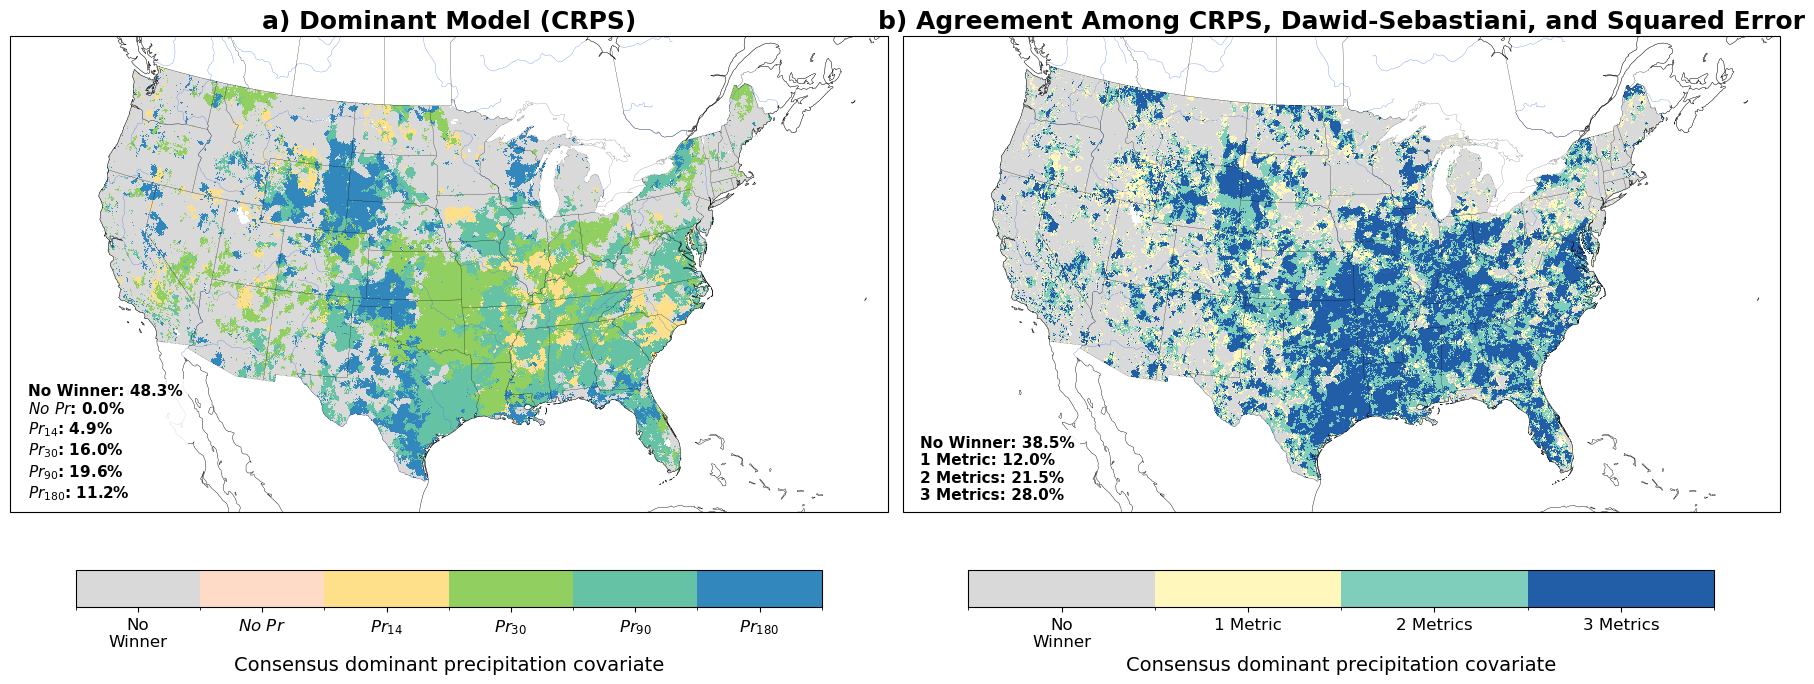

In [ ]:
dominant_cmap = mcolors.ListedColormap([
    "#d9d9d9",
    "#fddbc7",
    "#fee08b",
    "#91cf60",
    "#66c2a5",
    "#3288bd",
])
dominant_labels = [
    "No\nWinner",
    "$No$ $Pr$",
    "$Pr_{14}$",
    "$Pr_{30}$",
    "$Pr_{90}$",
    "$Pr_{180}$",
]
agreement_cmap = mcolors.ListedColormap(["#d9d9d9",  # No winner
    "#fff7bc",  # 1 metric
    "#7fcdbb",  # 2 metrics
    "#225ea8"])

agreement_norm = mcolors.BoundaryNorm( [-0.5, 0.5, 1.5, 2.5, 3.5], agreement_cmap.N)

agreement_labels = ["No\nWinner","1 Metric","2 Metrics","3 Metrics"]


dominant_norm = mcolors.BoundaryNorm(np.arange(-0.5, len(dominant_labels) + 0.5, 1), dominant_cmap.N,)

fig, axes = plt.subplots(1, 2,figsize=(18, 10),subplot_kw={"projection": proj})

plot_categorical_map( dominant_CRPS.where(landmask),title="", cmap=dominant_cmap,norm=dominant_norm, \
    cbar_labels=dominant_labels, proj=proj,ax=axes[0],state_borders=state_borders,rivers=rivers)
axes[0].set_title("a) Dominant Model (CRPS)",fontsize=18,weight='bold')
axes[0].tick_params(axis="both",labelsize=14)


plot_categorical_map(agreement_map.where(landmask), title="",\
    cmap=agreement_cmap, norm=agreement_norm, cbar_labels=agreement_labels,proj=proj,ax=axes[1],state_borders=state_borders,rivers=rivers)
axes[1].set_title("b) Agreement Among CRPS, Dawid-Sebastiani, and Squared Error",fontsize=18,weight='bold')


plt.tight_layout()
plt.show()



*Figure 1. Dominant antecedent precipitation timescales and agreement among predictive metrics. (a) Dominant antecedent precipitation timescale identified from cross-validated CRPS using pairwise Algorithm B1 comparisons. At each grid cell, the selected class corresponds to the precipitation accumulation period that yields the greatest number of statistically significant pairwise victories, with ties resolved using the lowest mean CRPS. (b) Agreement among CRPS, Dawid-Sebastiani score, and squared error, expressed as the number of metrics selecting the same dominant timescale. High agreement indicates that model-selection results are relatively insensitive to the choice of predictive metric. Together, these panels summarize the spatial structure and robustness of the dominant antecedent precipitation timescales across CONUS. The temperature-only (NoPr) class occurred at only four grid cells and is therefore omitted from subsequent distributional analyses.*

Dominant antecedent precipitation timescales exhibit coherent spatial structure and robust metric agreement. The next step is to determine whether these patterns can be explained by broad hydroclimatic gradients.

## Figure 2. Dominant Antecedent Precipitation Timescales and Annual Precipitation
Hypothesis: Is precipitation amount responsible?

In [34]:
records = []

for iclass, (label, period) in classes.items():
    vals = ( prcp_mean.where(dominant_CRPS.where(landmask) == iclass).values.ravel())
    vals = vals[np.isfinite(vals)]
    records.append( pd.DataFrame({"class": iclass, "label": label,"period": period,"ppt": vals}))

df = pd.concat(records, ignore_index=True)

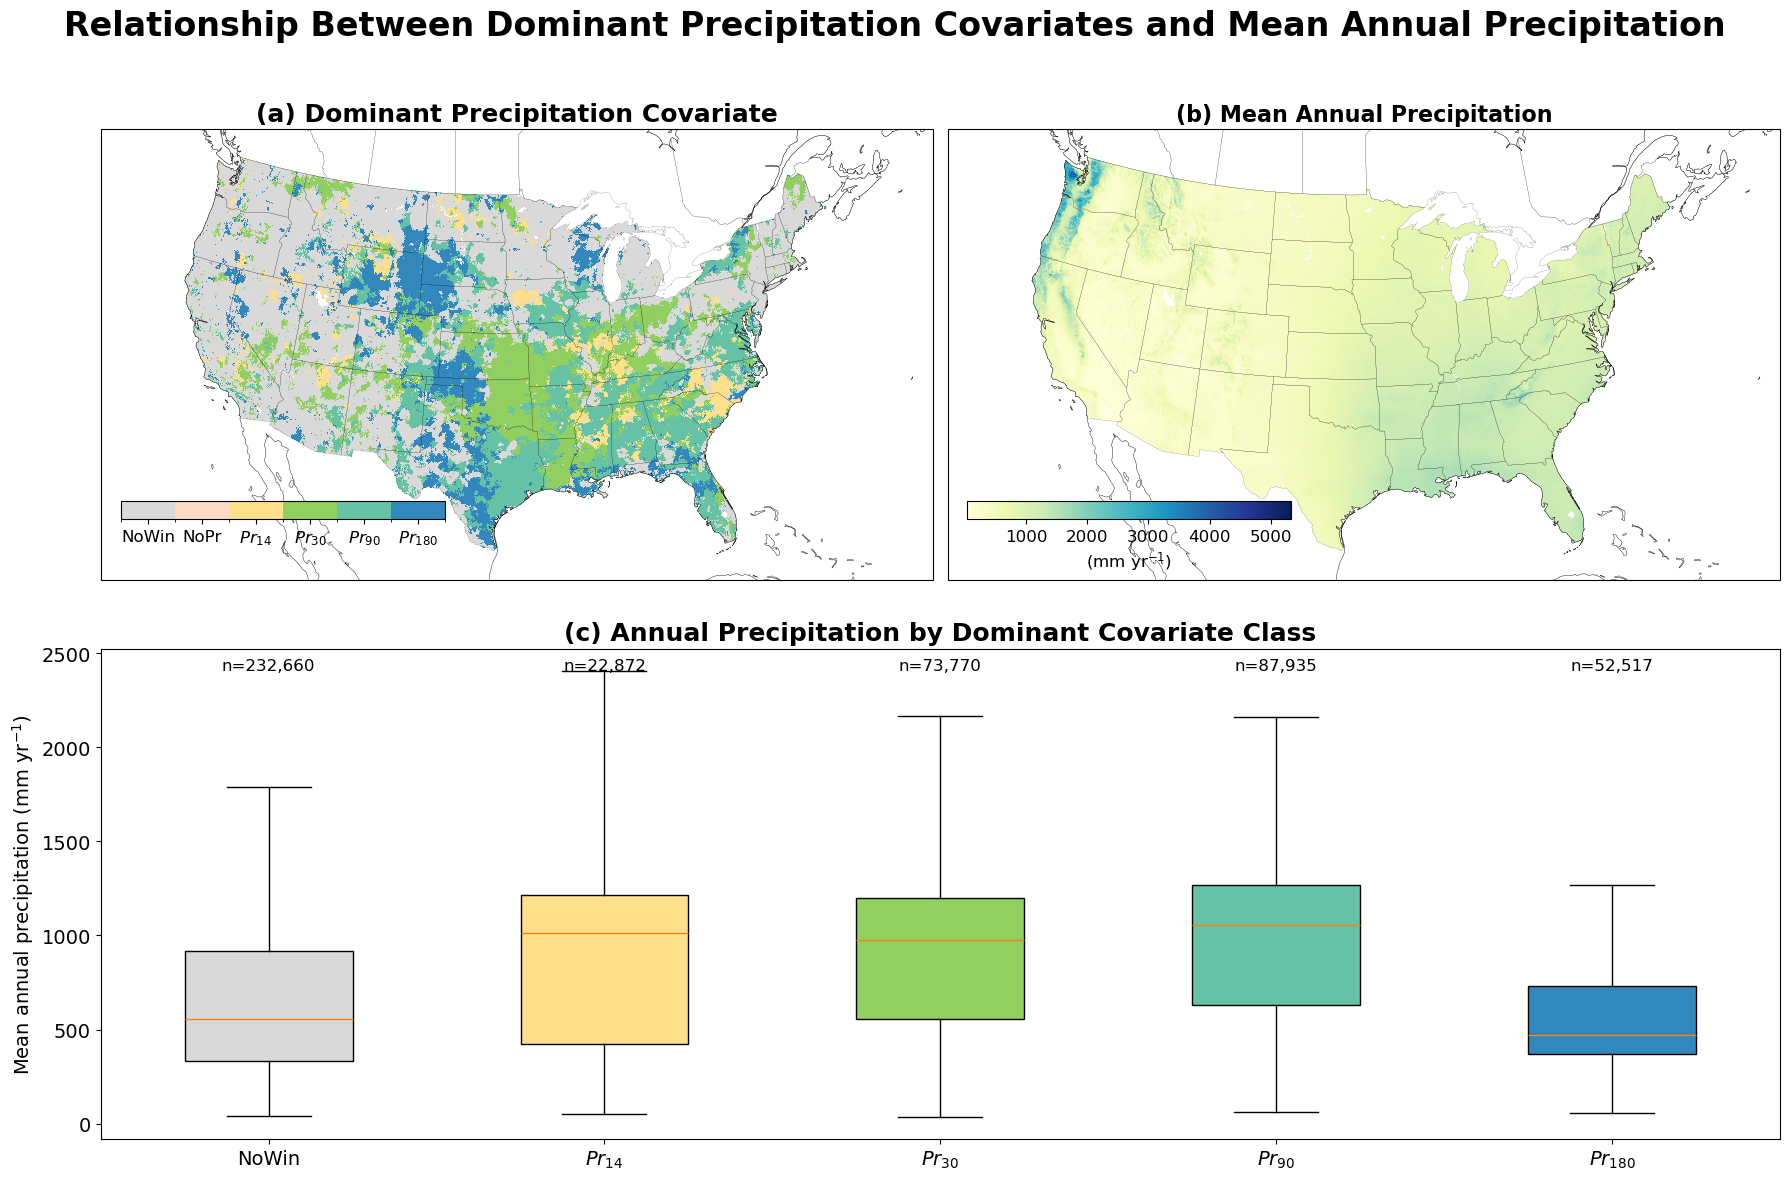

In [35]:
# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(18, 12))
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.1,top=0.95,hspace=0.1,wspace=0.04)
gs = GridSpec(2,2,figure=fig,height_ratios=[1, 0.8])
# ==================================================
# (a) Dominant covariate
# ==================================================
ax1 = fig.add_subplot(gs[0, 0],projection=proj)

im_a = plot_categorical_map(dominant_CRPS.where(landmask),title="(a) Dominant Precipitation Covariate",cmap=dominant_cmap,norm=dominant_norm,cbar_labels=dominant_labels,ax=ax1,\
    state_borders=state_borders,rivers=None,show_colorbar=False,show_percentages=False,)
# --------------------------------------------------
# Colorbar for panel (a)
# --------------------------------------------------
cax_dom = fig.add_axes( [0.07, 0.555, 0.18, 0.015])
ticks = (np.diff(dominant_norm.boundaries) / 2+ dominant_norm.boundaries[:-1])
cb_dom = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm),cax=cax_dom,orientation="horizontal",ticks=ticks)
cb_dom.ax.set_xticklabels([ "NoWin","NoPr", r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$"])
cb_dom.ax.tick_params(labelsize=12)
cb_dom.set_label("",fontsize=12)
# ==================================================
# (b) Annual precipitation map
# ==================================================
ax2 = fig.add_subplot(gs[0, 1],projection=proj)
im_p = prcp_mean.where(landmask).plot(ax=ax2,transform=ccrs.PlateCarree(),cmap="YlGnBu",add_colorbar=False)
ax2.coastlines(linewidth=0.3)

if state_borders is not None:
    ax2.add_feature( state_borders,edgecolor="k",linewidth=0.1,zorder=100)
ax2.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())

ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title("(b) Mean Annual Precipitation",fontsize=16,fontweight="bold",)
# --------------------------------------------------
# precipitation colorbar
# --------------------------------------------------
cax_p = fig.add_axes([0.54, 0.555, 0.18, 0.015])
cb_p = fig.colorbar(im_p,cax=cax_p,orientation="horizontal")
cb_p.ax.tick_params(labelsize=12)
cb_p.set_label(r"(mm yr$^{-1}$)",fontsize=12)

# ==================================================
# (c) Boxplot
# ==================================================
ax3 = fig.add_subplot(gs[1, :])

data = [df.loc[df["label"] == label,"ppt"]for label in order]
bp = ax3.boxplot(data,tick_labels=["NoWin",r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$",],showfliers=False,patch_artist=True,)

for box, color in zip(bp["boxes"],colors):
    box.set_facecolor(color)
ax3.set_ylabel(r"Mean annual precipitation (mm yr$^{-1}$)",fontsize=14)
ax3.set_title("(c) Annual Precipitation by Dominant Covariate Class",fontsize=18,fontweight="bold")
ax3.tick_params(axis="both",labelsize=14)
# sample size labels
for i, label in enumerate(order, start=1):
    n = (df["label"] == label).sum()
    ax3.text( i,ax3.get_ylim()[1] * 0.98,f"n={n:,}",ha="center",va="top",fontsize=12)

fig.suptitle("Relationship Between Dominant Precipitation Covariates and Mean Annual Precipitation",fontsize=24,fontweight="bold",)
plt.tight_layout()
plt.show()

*Figure 2. Relationship between dominant antecedent precipitation timescales and mean annual precipitation. (a) Dominant antecedent precipitation timescale identified from cross-validated CRPS. (b) Mean annual precipitation climatology derived from NClimGrid daily precipitation observations. (c) Distribution of mean annual precipitation associated with NoWin, $Pr_{14}$, $Pr_{30}$, $Pr_{90}$, and $Pr_{180}$; sample sizes are indicated above each boxplot. Regions classified as NoWin generally occur in drier environments than regions where precipitation covariates improve predictive skill. However, substantial overlap among the precipitation distributions associated with $Pr_{14}$, $Pr_{30}$, $Pr_{90}$, and $Pr_{180}$ indicates that annual precipitation alone provides limited separation among dominant antecedent precipitation timescales.*

Annual precipitation provides only limited separation among dominant-timescale classes, motivating examination of environmental characteristics more closely related to hydrologic storage and landscape structure.

## Figure 3. Dominant Antecedent Precipitation Timescales and Elevation
Hypothesis: Topographic controls weaken the influence of precipitation accumulation period on heat extremes.

In [29]:
records = []
for iclass, (label, period) in classes.items():
    vals = topo_regrid.where(dominant_CRPS.where(landmask) == iclass).values.ravel()
    vals = vals[np.isfinite(vals)]
    records.append( pd.DataFrame({"class": iclass, "label": label,"period": period,"elev": vals}))    
df = pd.concat(records, ignore_index=True)

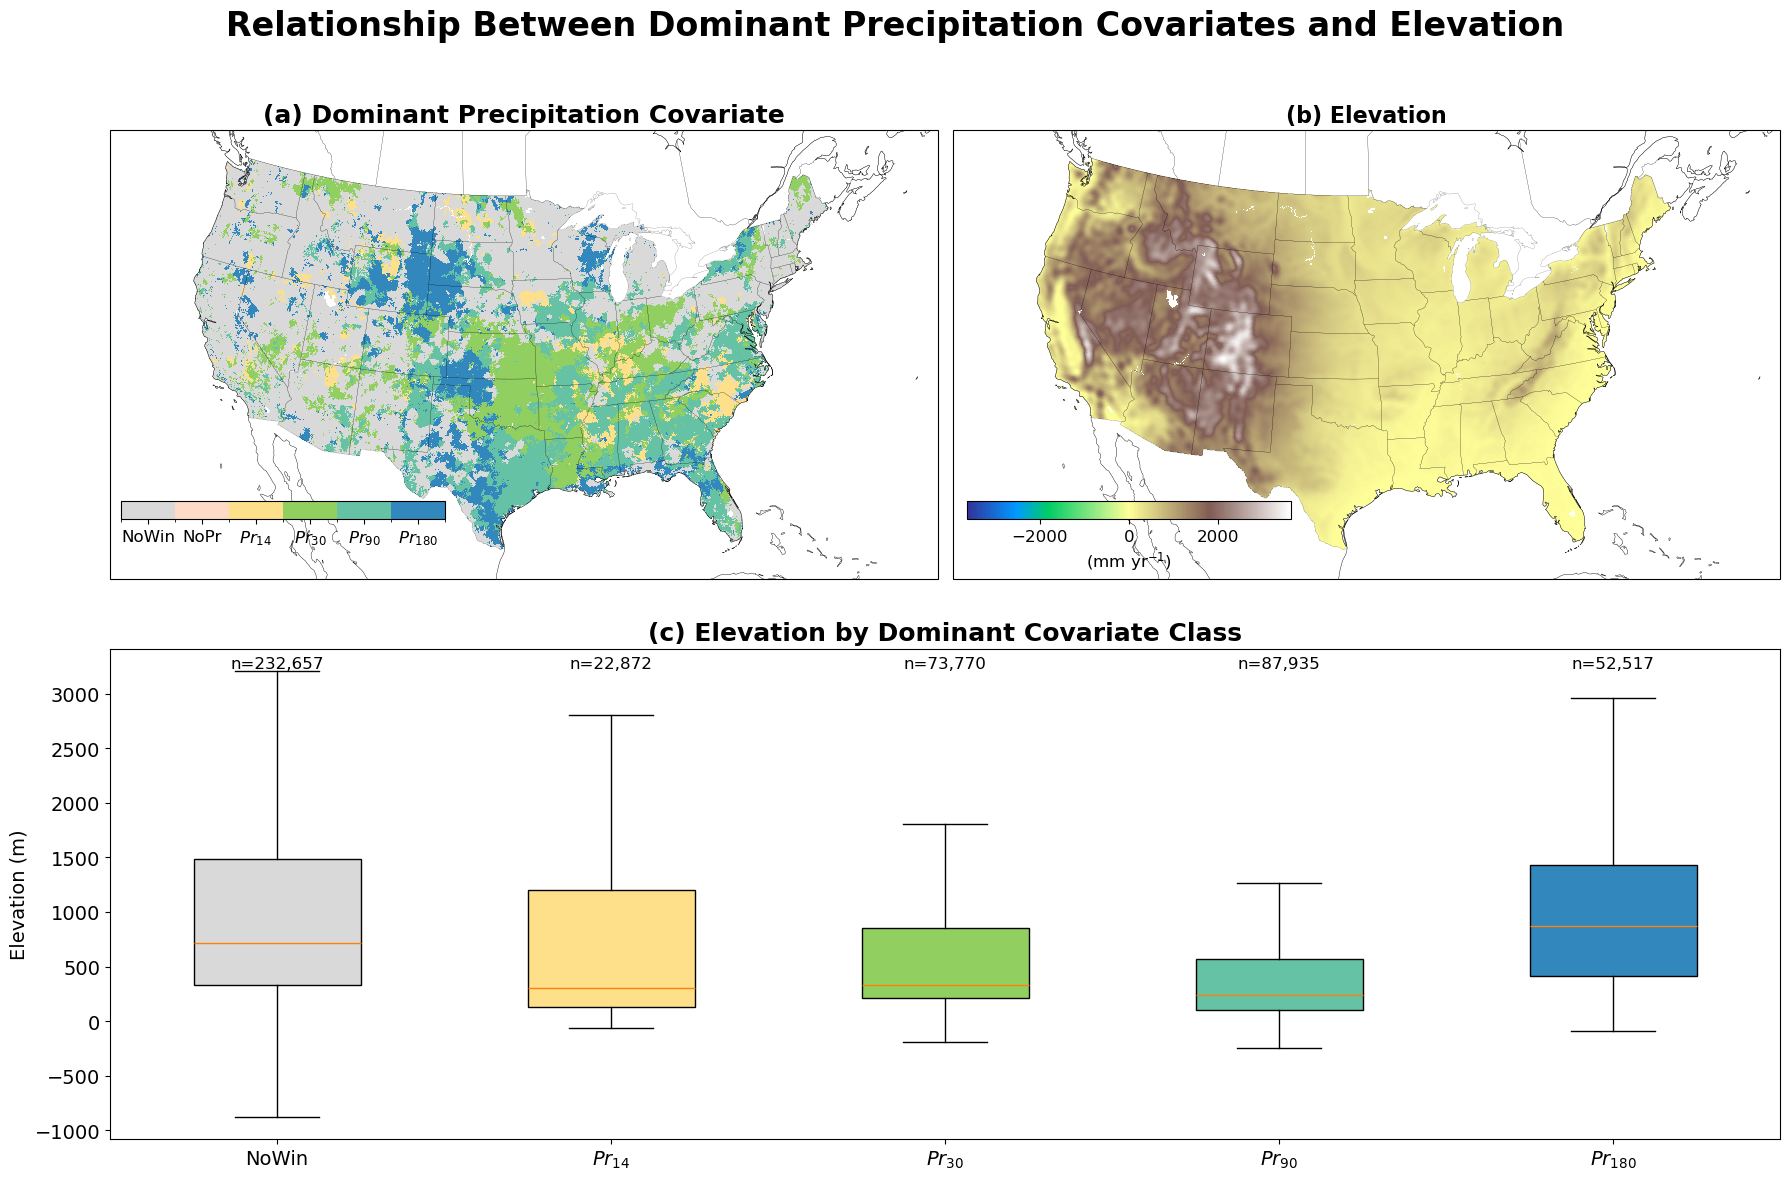

In [33]:
# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(18, 12))
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.1,top=0.95,hspace=0.1,wspace=0.04)
gs = GridSpec(2,2,figure=fig,height_ratios=[1, 0.8])
# ==================================================
# (a) Dominant covariate
# ==================================================
ax1 = fig.add_subplot(gs[0, 0],projection=proj)

im_a = plot_categorical_map(dominant_CRPS.where(landmask),title="(a) Dominant Precipitation Covariate",cmap=dominant_cmap,norm=dominant_norm,cbar_labels=dominant_labels,ax=ax1,\
    state_borders=state_borders,rivers=None,show_colorbar=False,show_percentages=False,)
# --------------------------------------------------
# Colorbar for panel (a)
# --------------------------------------------------
cax_dom = fig.add_axes( [0.07, 0.555, 0.18, 0.015])
ticks = (np.diff(dominant_norm.boundaries) / 2+ dominant_norm.boundaries[:-1])
cb_dom = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm),cax=cax_dom,orientation="horizontal",ticks=ticks)
cb_dom.ax.set_xticklabels([ "NoWin","NoPr", r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$"])
cb_dom.ax.tick_params(labelsize=12)
cb_dom.set_label("",fontsize=12)
# ==================================================
# (b) Annual precipitation map
# ==================================================
ax2 = fig.add_subplot(gs[0, 1],projection=proj)
im_p = topo_regrid.where(landmask).plot(ax=ax2,transform=ccrs.PlateCarree(),cmap="terrain",add_colorbar=False)
ax2.coastlines(linewidth=0.3)

if state_borders is not None:
    ax2.add_feature( state_borders,edgecolor="k",linewidth=0.1,zorder=100)
ax2.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())

ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title("(b) Elevation",fontsize=16,fontweight="bold",)
# --------------------------------------------------
# precipitation colorbar
# --------------------------------------------------
cax_p = fig.add_axes([0.54, 0.555, 0.18, 0.015])
cb_p = fig.colorbar(im_p,cax=cax_p,orientation="horizontal")
cb_p.ax.tick_params(labelsize=12)
cb_p.set_label(r"(mm yr$^{-1}$)",fontsize=12)

# ==================================================
# (c) Boxplot
# ==================================================
ax3 = fig.add_subplot(gs[1, :])

data = [df.loc[df["label"] == label,"elev"]for label in order]
bp = ax3.boxplot(data,tick_labels=["NoWin",r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$",],showfliers=False,patch_artist=True,)

for box, color in zip(bp["boxes"],colors):
    box.set_facecolor(color)
ax3.set_ylabel(r"Elevation (m)",fontsize=14)
ax3.set_title("(c) Elevation by Dominant Covariate Class",fontsize=18,fontweight="bold")
ax3.tick_params(axis="both",labelsize=14)
# sample size labels
for i, label in enumerate(order, start=1):
    n = (df["label"] == label).sum()
    ax3.text( i,ax3.get_ylim()[1] * 0.98,f"n={n:,}",ha="center",va="top",fontsize=12)

fig.suptitle("Relationship Between Dominant Precipitation Covariates and Elevation",fontsize=24,fontweight="bold",)
plt.tight_layout()
plt.show()

*Figure 3. Relationship between dominant antecedent precipitation timescales and elevation. (a) Dominant antecedent precipitation timescale identified from cross-validated CRPS. (b) Topography of the continental United States. (c) Distribution of elevation associated with each dominant-timescale class; sample sizes are indicated above each boxplot. Elevation exhibits substantially clearer differences among classes than annual precipitation. Regions favoring $Pr_{90}$ generally occur at lower elevations, whereas $Pr_{180}$ occurs more frequently in higher-elevation environments. The NoWin class is also associated with elevated and topographically complex regions, suggesting that topographic setting is strongly related to dominant antecedent precipitation timescale.*

The stronger relationship with elevation suggests that topography controls may be important. To examine whether subsurface moisture conditions provide additional explanatory power, root-zone soil moisture is considered next.

## Figure 4. Dominant Antecedent Precipitation Timescales and Root-Zone Soil Moisture
Is soil moisture important?

In [36]:
records = []
for iclass, (label, period) in classes.items():
    vals = sm_mean.where(dominant_CRPS.where(landmask) == iclass).values.ravel()
    vals = vals[np.isfinite(vals)]
    records.append( pd.DataFrame({"class": iclass, "label": label,"soil_moisture": vals}))    
df = pd.concat(records, ignore_index=True)

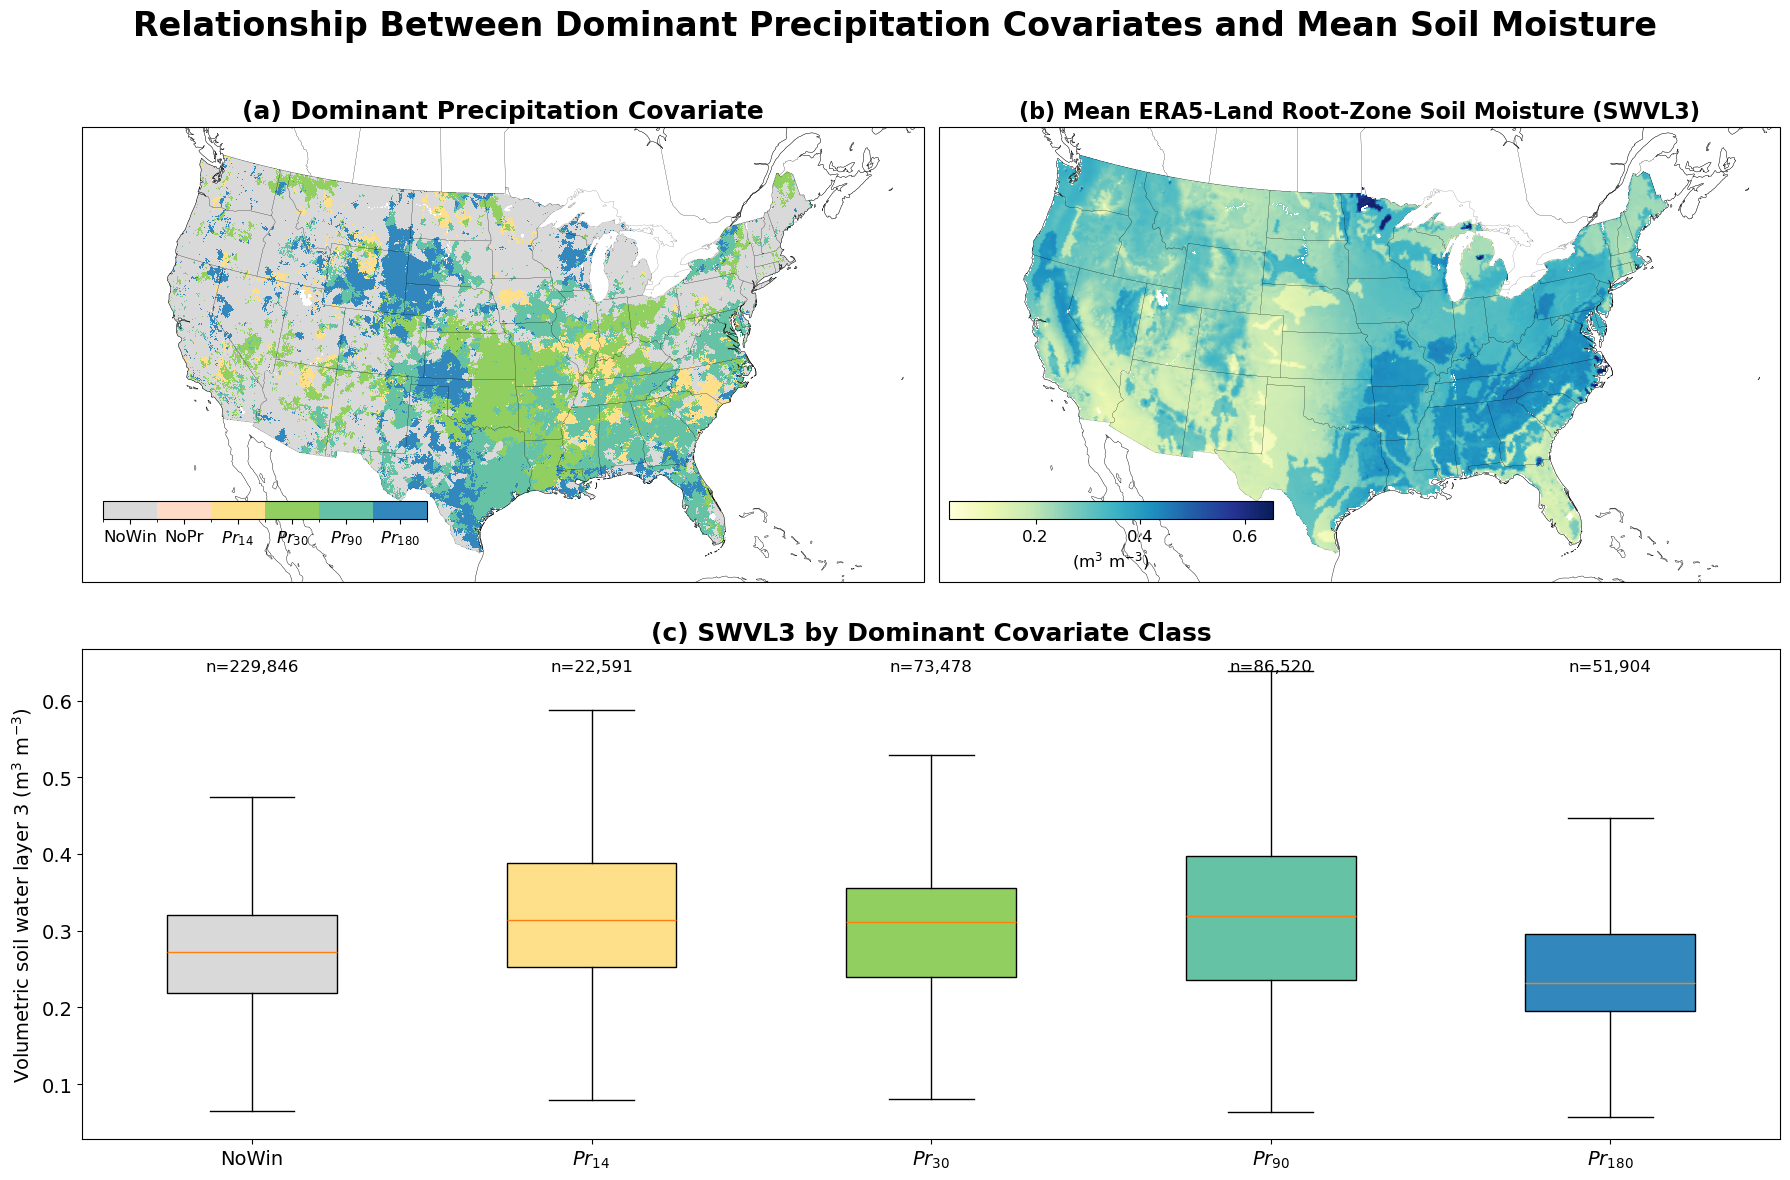

In [37]:
# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(18, 12))
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.1,top=0.95,hspace=0.1,wspace=0.04)
gs = GridSpec(2,2,figure=fig,height_ratios=[1, 0.8])
# ==================================================
# (a) Dominant covariate
# ==================================================
ax1 = fig.add_subplot(gs[0, 0],projection=proj)

im_a = plot_categorical_map(dominant_CRPS.where(landmask),title="(a) Dominant Precipitation Covariate",cmap=dominant_cmap,norm=dominant_norm,cbar_labels=dominant_labels,ax=ax1,\
    state_borders=state_borders,rivers=None,show_colorbar=False,show_percentages=False,)
# --------------------------------------------------
# Colorbar for panel (a)
# --------------------------------------------------
cax_dom = fig.add_axes( [0.06, 0.555, 0.18, 0.015])
ticks = (np.diff(dominant_norm.boundaries) / 2+ dominant_norm.boundaries[:-1])
cb_dom = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm),cax=cax_dom,orientation="horizontal",ticks=ticks)
cb_dom.ax.set_xticklabels([ "NoWin","NoPr", r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$"])
cb_dom.ax.tick_params(labelsize=12)
cb_dom.set_label("",fontsize=12)
# ==================================================
# (b) Annual precipitation map
# ==================================================
ax2 = fig.add_subplot(gs[0, 1],projection=proj)
im_p = sm_mean.where(landmask).plot(ax=ax2,transform=ccrs.PlateCarree(),cmap="YlGnBu",add_colorbar=False)
ax2.coastlines(linewidth=0.3)

if state_borders is not None:
    ax2.add_feature( state_borders,edgecolor="k",linewidth=0.1,zorder=100)
ax2.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())

ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title("(b) Mean ERA5-Land Root-Zone Soil Moisture (SWVL3)",fontsize=16,fontweight="bold",)
# --------------------------------------------------
# precipitation colorbar
# --------------------------------------------------
cax_p = fig.add_axes([0.53, 0.555, 0.18, 0.015])
cb_p = fig.colorbar(im_p,cax=cax_p,orientation="horizontal")
cb_p.ax.tick_params(labelsize=12)
cb_p.set_label(r"(m$^{3}$ m$^{-3}$)",fontsize=12)

# ==================================================
# (c) Boxplot
# ==================================================
ax3 = fig.add_subplot(gs[1, :])

data = [df.loc[df["label"] == label,"soil_moisture"]for label in order]
bp = ax3.boxplot(data,tick_labels=["NoWin",r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$",],showfliers=False,patch_artist=True,)

for box, color in zip(bp["boxes"],colors):
    box.set_facecolor(color)
ax3.set_ylabel(r"Volumetric soil water layer 3 (m$^{3}$ m$^{-3}$)",fontsize=14)
ax3.set_title("(c) SWVL3 by Dominant Covariate Class",fontsize=18,fontweight="bold")
ax3.tick_params(axis="both",labelsize=14)
# sample size labels
for i, label in enumerate(order, start=1):
    n = (df["label"] == label).sum()
    ax3.text( i,ax3.get_ylim()[1] * 0.98,f"n={n:,}",ha="center",va="top",fontsize=12)

fig.suptitle("Relationship Between Dominant Precipitation Covariates and Mean Soil Moisture",fontsize=24,fontweight="bold",)
plt.tight_layout()
plt.show()

*Figure 4. Relationship between dominant antecedent precipitation timescales and root-zone soil moisture. (a) Dominant antecedent precipitation timescale identified from cross-validated CRPS. (b) Mean ERA5-Land volumetric soil water content in layer 3 (SWVL3; 28–100 cm depth). (c) Distribution of mean SWVL3 associated with each dominant-timescale class; sample sizes are indicated above each boxplot. Root-zone soil moisture provides clearer separation among dominant-timescale classes than annual precipitation. Regions favoring $Pr_{90}$ are generally associated with relatively moist soils, whereas regions favoring $Pr_{180}$ occur more frequently in environments characterized by lower SWVL3 values.*

Root-zone soil moisture exhibits clearer separation than precipitation amount alone. Figure 5 combines soil moisture and elevation to characterize the hydroclimatic environments occupied by each dominant-timescale class.

## Figure 5. Hydroclimatic Environments of Dominant Timescales
 What hydroclimatic environments do the classes occupy?

In [38]:
records = []

for iclass, (label, period) in classes.items():
    elev = topo_regrid.where(dominant_CRPS.where(landmask) == iclass).values.ravel()
    sm = sm_mean.where(dominant_CRPS == iclass).values.ravel()
    valid = np.isfinite(elev) & np.isfinite(sm)
    records.append(pd.DataFrame({"class": iclass,"label": label,"elevation": elev[valid],"swvl3": sm[valid],}))
df_env = pd.concat(records,ignore_index=True,)

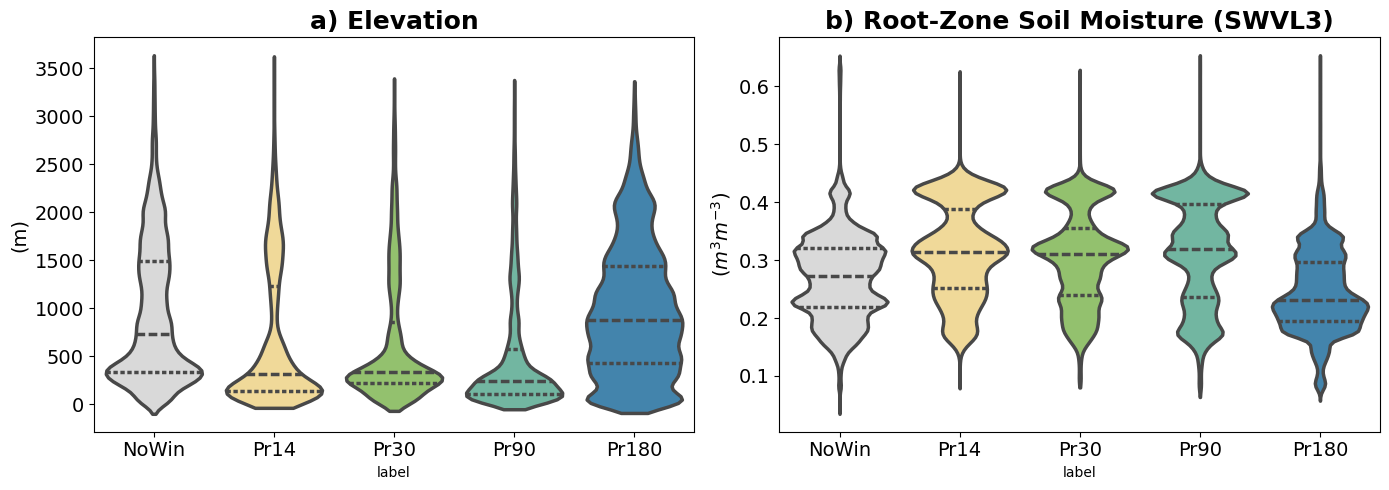

In [42]:
fig, axes = plt.subplots(1, 2,figsize=(14, 5))

sns.violinplot(data=df_env,x="label",y="elevation",order=order,palette=palette,inner="quart",linewidth=2.5,cut=0,ax=axes[0])
axes[0].set_title("a) Elevation",fontsize=18,weight='bold')
axes[0].set_ylabel("(m)",fontsize=14)
axes[0].tick_params(axis="both",labelsize=14)


sns.violinplot(data=df_env,x="label",y="swvl3",order=order,palette=palette,inner="quart",linewidth=2.5,cut=0,ax=axes[1])
axes[1].set_title("b) Root-Zone Soil Moisture (SWVL3)",fontsize=18,weight='bold')
axes[1].set_ylabel("($m^3 m^{-3})$",fontsize=14)
axes[1].tick_params(axis="both",labelsize=14)

plt.tight_layout()
plt.show()

*Figure 5. Elevation and root-zone soil moisture associated with dominant antecedent precipitation timescales. Violin plots show the distributions of (a) elevation and (b) mean ERA5-Land root-zone soil moisture (SWVL3; 28–100 cm depth) for grid cells classified according to their dominant antecedent precipitation timescale. Dashed lines indicate the 25th, 50th (median), and 75th percentiles. Regions favoring $Pr_{90}$ are generally characterized by lower elevations and relatively moist soils, whereas regions favoring $Pr_{180}$ are associated with higher elevations and lower root-zone soil moisture. These distributions synthesize the patterns identified in Figures 3 and 4 and indicate that dominant antecedent precipitation timescales occupy distinct hydroclimatic settings.*

Having identified distinct environmental settings associated with dominant antecedent precipitation timescales, the final analysis examines whether these classes also differ in their estimated sensitivity of extreme-temperature return levels to large-scale climate variability and change.

## Figure 6. Return-Level Sensitivity and Dominant Antecedent Precipitation Timescales
Do dominant antecedent precipitation timescales correspond to differences in the estimated sensitivity of extreme temperatures to warming?

In [43]:
def compute_rl_sensitivity(ds, rp=20):
    """
    Return-level sensitivity to GLOST.
    Units:
        °F per °C GLOST
    """
    rl = ds.rl.sel(return_periods=rp)
    d_rl = rl.isel(time=-1)- rl.isel(time=0)
    d_glost = float(ds.covariate1.isel(time=-1).mean({'lon','lat'})- ds.covariate1.isel(time=0).mean({'lon','lat'}))

    return d_rl / d_glost

In [44]:
sens_NoPr = compute_rl_sensitivity(datasets["PrNO"],rp=20)
sens_Pr14 = compute_rl_sensitivity(datasets["Pr14"],rp=20)
sens_Pr30 = compute_rl_sensitivity(datasets["Pr30"],rp=20)
sens_Pr90 = compute_rl_sensitivity(datasets["Pr90"],rp=20)
sens_Pr180 = compute_rl_sensitivity(datasets["Pr180"],rp=20)

dS_Pr14 = sens_Pr14 - sens_NoPr
dS_Pr30 = sens_Pr30 - sens_NoPr
dS_Pr90 = sens_Pr90 - sens_NoPr
dS_Pr180 = sens_Pr180 - sens_NoPr

dS_dom = xr.full_like(dominant_CRPS,np.nan,dtype=float,)
dS_dom = xr.where(dominant_CRPS == 2,dS_Pr14,dS_dom,)
dS_dom = xr.where(dominant_CRPS == 3,dS_Pr30,dS_dom)
dS_dom = xr.where(dominant_CRPS == 4,dS_Pr90,dS_dom)
dS_dom = xr.where(dominant_CRPS == 5,dS_Pr180,dS_dom)
dS_dom = dS_dom.where(landmask)
dS_dom.attrs["long_name"] = ("Return-level sensitivity difference ""relative to NoPr")
dS_dom.attrs["units"] = "degF per degC GLOST"

In [46]:
records = []

for iclass, (label, period) in classes.items():
    vals = dS_dom.where(dominant_CRPS.where(landmask) == iclass).values.ravel()
    vals = vals[np.isfinite(vals)]
    records.append(pd.DataFrame({"class": iclass, "label": label,"dS": vals}))

df = pd.concat(records,ignore_index=True)

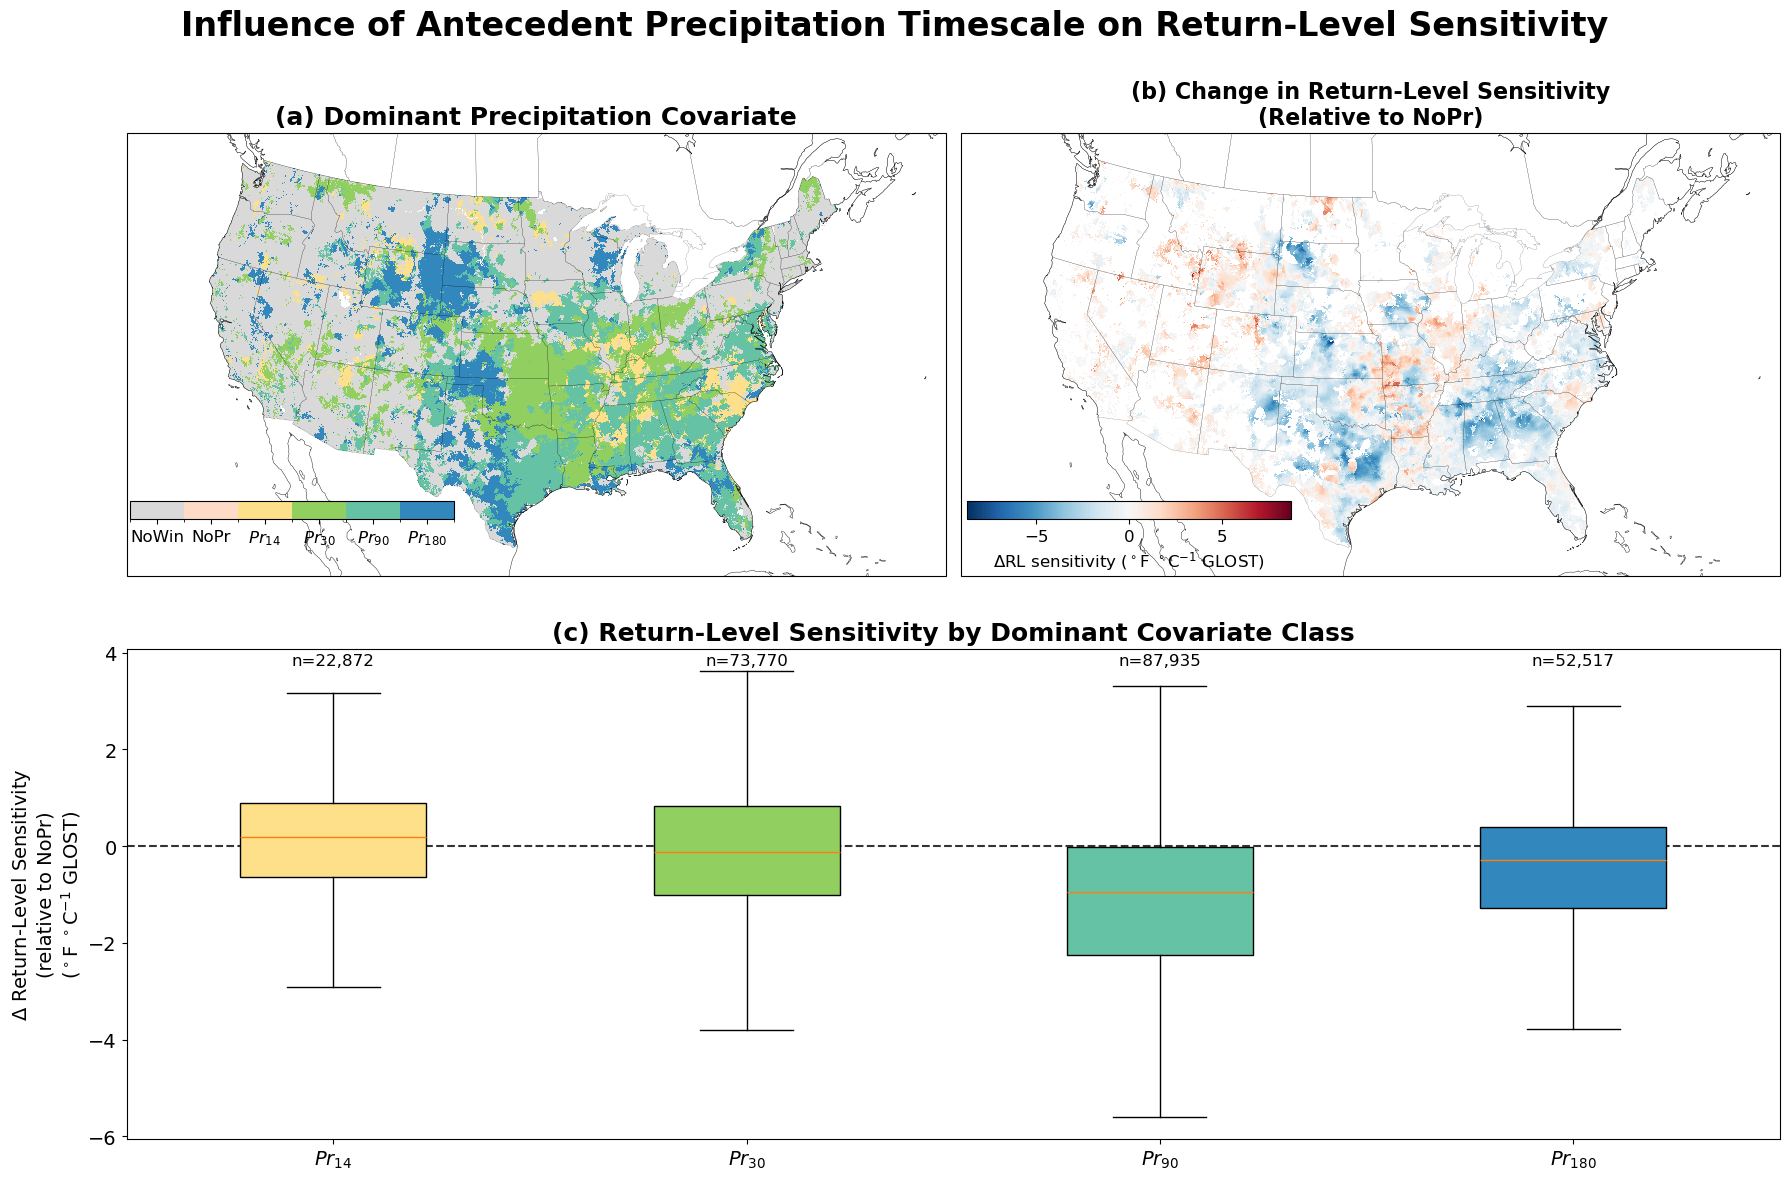

In [51]:
# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(18, 12))
plt.subplots_adjust(left=0.05,right=0.95,bottom=0.1,top=0.95,hspace=0.1,wspace=0.04)
gs = GridSpec(2,2,figure=fig,height_ratios=[1, 0.8])
# ==================================================
# (a) Dominant covariate
# ==================================================
ax1 = fig.add_subplot(gs[0, 0],projection=proj)

im_a = plot_categorical_map(dominant_CRPS.where(landmask),title="(a) Dominant Precipitation Covariate",cmap=dominant_cmap,norm=dominant_norm,cbar_labels=dominant_labels,ax=ax1,\
    state_borders=state_borders,rivers=None,show_colorbar=False,show_percentages=False,)
# --------------------------------------------------
# Colorbar for panel (a)
# --------------------------------------------------
cax_dom = fig.add_axes( [0.075, 0.555, 0.18, 0.015])
ticks = (np.diff(dominant_norm.boundaries) / 2+ dominant_norm.boundaries[:-1])
cb_dom = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm),cax=cax_dom,orientation="horizontal",ticks=ticks)
cb_dom.ax.set_xticklabels([ "NoWin","NoPr", r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$"])
cb_dom.ax.tick_params(labelsize=12)
cb_dom.set_label("",fontsize=12)
# ==================================================
# (b) Annual precipitation map
# ==================================================
ax2 = fig.add_subplot(gs[0, 1],projection=proj)
im_p = dS_dom.where(landmask).plot(ax=ax2,transform=ccrs.PlateCarree(),cmap="RdBu_r",add_colorbar=False)
ax2.coastlines(linewidth=0.3)

if state_borders is not None:
    ax2.add_feature( state_borders,edgecolor="k",linewidth=0.1,zorder=100)
ax2.set_extent((-125, -66.5, 24, 50),crs=ccrs.PlateCarree())

ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_title("(b) Change in Return-Level Sensitivity\n(Relative to NoPr)",fontsize=16,fontweight="bold",)
# --------------------------------------------------
# precipitation colorbar
# --------------------------------------------------
cax_p = fig.add_axes([0.54, 0.555, 0.18, 0.015])
cb_p = fig.colorbar(im_p,cax=cax_p,orientation="horizontal")
cb_p.ax.tick_params(labelsize=12)
cb_p.set_label(r"$\Delta$RL sensitivity "
    r"($^\circ$F $^\circ$C$^{-1}$ GLOST)",fontsize=12)

# ==================================================
# (c) Boxplot
# ==================================================
ax3 = fig.add_subplot(gs[1, :])

data = [df.loc[df["label"] == label,"dS"]for label in order[1:]]
bp = ax3.boxplot(data,tick_labels=[r"$Pr_{14}$",r"$Pr_{30}$",r"$Pr_{90}$",r"$Pr_{180}$",],showfliers=False,patch_artist=True,)

for box, color in zip(bp["boxes"],colors[1:]):
    box.set_facecolor(color)
ax3.axhline(y=0,color="black",linestyle="--",linewidth=1.5,alpha=0.8,zorder=0)    
ax3.set_ylabel(r"$\Delta$ Return-Level Sensitivity"
    "\n(relative to NoPr)"
    "\n($^\circ$F $^\circ$C$^{-1}$ GLOST)",fontsize=14)
ax3.set_title("(c) Return-Level Sensitivity by Dominant Covariate Class",fontsize=18,fontweight="bold")
ax3.tick_params(axis="both",labelsize=14)
# sample size labels
for i, label in enumerate(order[1:], start=1):
    n = (df["label"] == label).sum()
    ax3.text( i,ax3.get_ylim()[1] * 0.98,f"n={n:,}",ha="center",va="top",fontsize=12)

fig.suptitle("Influence of Antecedent Precipitation Timescale on Return-Level Sensitivity",fontsize=24,fontweight="bold",)
plt.tight_layout()
plt.show()

Figure 6. Relationship between dominant antecedent precipitation timescales and return-level sensitivity to warming. (a) Dominant antecedent precipitation timescale identified from cross-validated CRPS. (b) Difference in 20-year return-level sensitivity to GLOST relative to the corresponding temperature-only model ($NoPr$). Positive values indicate higher estimated sensitivity in the precipitation-based model, whereas negative values indicate lower estimated sensitivity relative to $NoPr$. (c) Distribution of return-level sensitivity differences associated with $NoWin$, $Pr_{14}$, $Pr_{30}$, $Pr_{90}$, and $Pr_{180}$; sample sizes are indicated above each boxplot. Median sensitivity differences vary among classes, with $Pr_{90}$ and $Pr_{180}$ generally exhibiting more negative values than $Pr_{14}$ and $Pr_{30}$. However, substantial overlap among the distributions indicates that return-level sensitivity is not uniquely associated with any individual antecedent precipitation timescale.

## Conclusion and Future Work

# Conclusion and Future Work

### Key Findings

- Cross-validated model comparisons identified geographically coherent dominant antecedent precipitation timescales across CONUS, with $Pr_{30}$, $Pr_{90}$, and $Pr_{180}$ emerging as the preferred predictors in distinct regions.
- Annual and winter precipitation provided limited separation among dominant-timescale classes, indicating that precipitation amount alone does not explain the preferred antecedent precipitation timescale.
- Elevation and root-zone soil moisture (ERA5-Land SWVL3) emerged as the strongest environmental discriminators. 
    - Regions favoring $Pr_{90}$ generally occur at lower elevations and under relatively moist soil conditions.
    - Regions favoring $Pr_{180}$ occur more frequently in higher-elevation environments with lower root-zone soil moisture.
- Return-level sensitivity analyses suggest that models favoring different antecedent precipitation timescales can yield different estimates of the sensitivity of temperature extremes to large-scale warming.

### Main Conclusion

The results indicate that dominant antecedent precipitation timescales are more strongly associated with hydroclimatic and physiographic conditions than with precipitation amount alone. In particular, elevation and root-zone soil moisture provide the clearest separation among timescale classes, suggesting that land-surface moisture conditions are closely linked to the antecedent precipitation information that most improves the prediction of temperature extremes.

### Limitations

- The analysis identifies statistical associations and does not establish causal mechanisms.
- Only four antecedent precipitation accumulation periods (14, 30, 90, and 180 days) were evaluated.
- Environmental analyses were based primarily on climatological fields and therefore do not explicitly capture seasonal evolution, interannual variability, or transient land-atmosphere interactions.
- The dominant-timescale framework was evaluated for warm-temperature extremes and may not generalize to other hazards or seasons without additional testing.

### Future Work

A key next step is the development of a **machine-learning framework for predicting dominant antecedent precipitation timescales** from hydroclimatic and physiographic conditions.

- Use the dominant-timescale classifications developed here as a supervised-learning target variable.
- Train machine-learning models using predictors such as: 
    - root-zone soil moisture,
    - seasonal and annual precipitation,
    - elevation and terrain characteristics,
    - snow-related variables,
    - vegetation and land-cover information,
    - aridity and land-surface moisture indicators.
- Quantify the relative importance of environmental controls governing timescale selection across regions and climate regimes.
- Generate spatially explicit predictions of the antecedent precipitation timescale most relevant for extreme-temperature modeling, including regions where observations are sparse.
- Evaluate whether machine-learning-derived timescales can improve nonstationary extreme-value analyses relative to a fixed set of candidate accumulation periods.

From a NOAA perspective, this work provides a pathway toward **process-informed, regionally adaptive predictors of extreme heat risk**. A machine-learning framework capable of identifying the most relevant antecedent moisture timescale from environmental conditions could support climate monitoring, subseasonal-to-seasonal forecasting, extreme-event attribution, and heat-warning applications. More broadly, this approach offers a framework for linking hydroclimatic conditions to the evolving risk of temperature extremes under climate variability and change.


